SARIMAX Baseline model

importing the master_dataset from the data collection python file

Pulling Financial Market Data...
Fetching market data from 2016-01-01 to 2026-07-24


/var/folders/2c/yb6xjdp11v57x1r5bk7tndtm0000gn/T/ipykernel_4543/359705254.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  raw_data = yf.download(tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  4 of 4 completed


Downsampling to uniform weekly frequency (Friday close)
Pulling OPEC+ Supply Data...
Merging into Master Matrix...

--- Dynamically Pulled Cleaned Weekly Dataset ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-06-26    71.989998  69.230003       101.360001  18.410000   
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998       100.750000  18.770000   
2026-07-24   100.519997  92.190002       101.436996  18.700001   

            OPEC_Plus_Production  
2026-06-26             26.937156  
2026-07-03             27.516865  
2026-07-10             27.516865  
2026-07-17             27.516865  
2026-07-24             27.516865  
--- Summary Statistics ---
       Brent_Crude   WTI_Crude  US_Dollar_Index   VIX_Index  \
count   551.000000  551.000000       551.000000  551.000000   
mean     69.056860   64.713085        98.558343   18.317786   
std      18

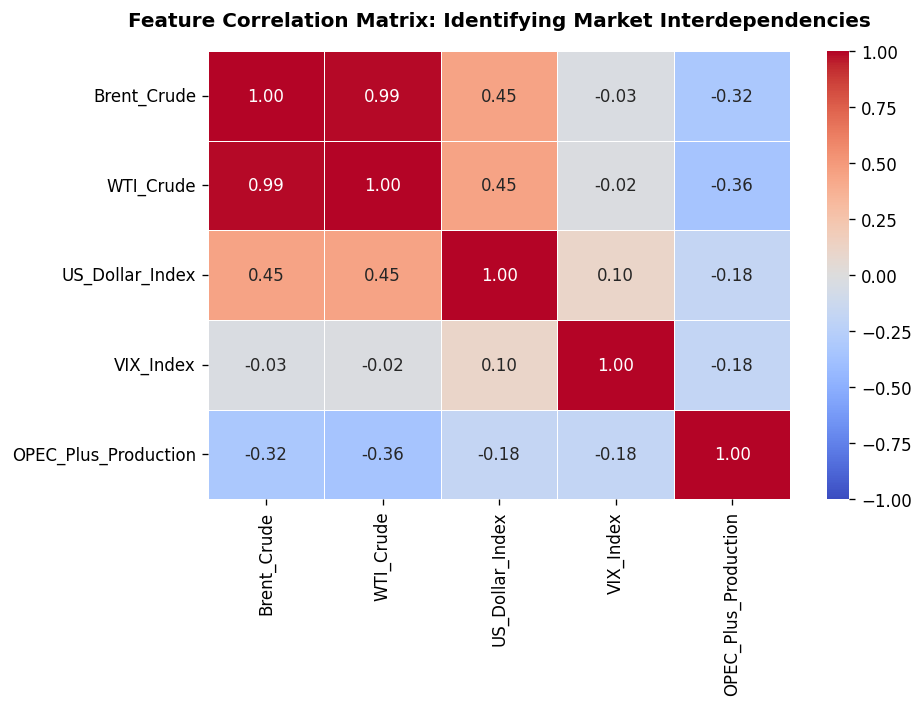

Normalization complete! New columns added to master_dataset.

--- Raw vs Normalized Dataset ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-06-26    71.989998  69.230003       101.360001  18.410000   
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004       100.970001  15.030000   
2026-07-17    88.099998  82.489998       100.750000  18.770000   
2026-07-24   100.519997  92.190002       101.436996  18.700001   

            OPEC_Plus_Production  
2026-06-26             26.937156  
2026-07-03             27.516865  
2026-07-10             27.516865  
2026-07-17             27.516865  
2026-07-24             27.516865  

--- Smoothed Dataset (SMA, EMA and Rolling Median included) ---
            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  \
2026-06-26    71.989998  69.230003       101.360001  18.410000   
2026-07-03    71.800003  68.690002       100.860001  16.150000   
2026-07-10    76.010002  71.410004

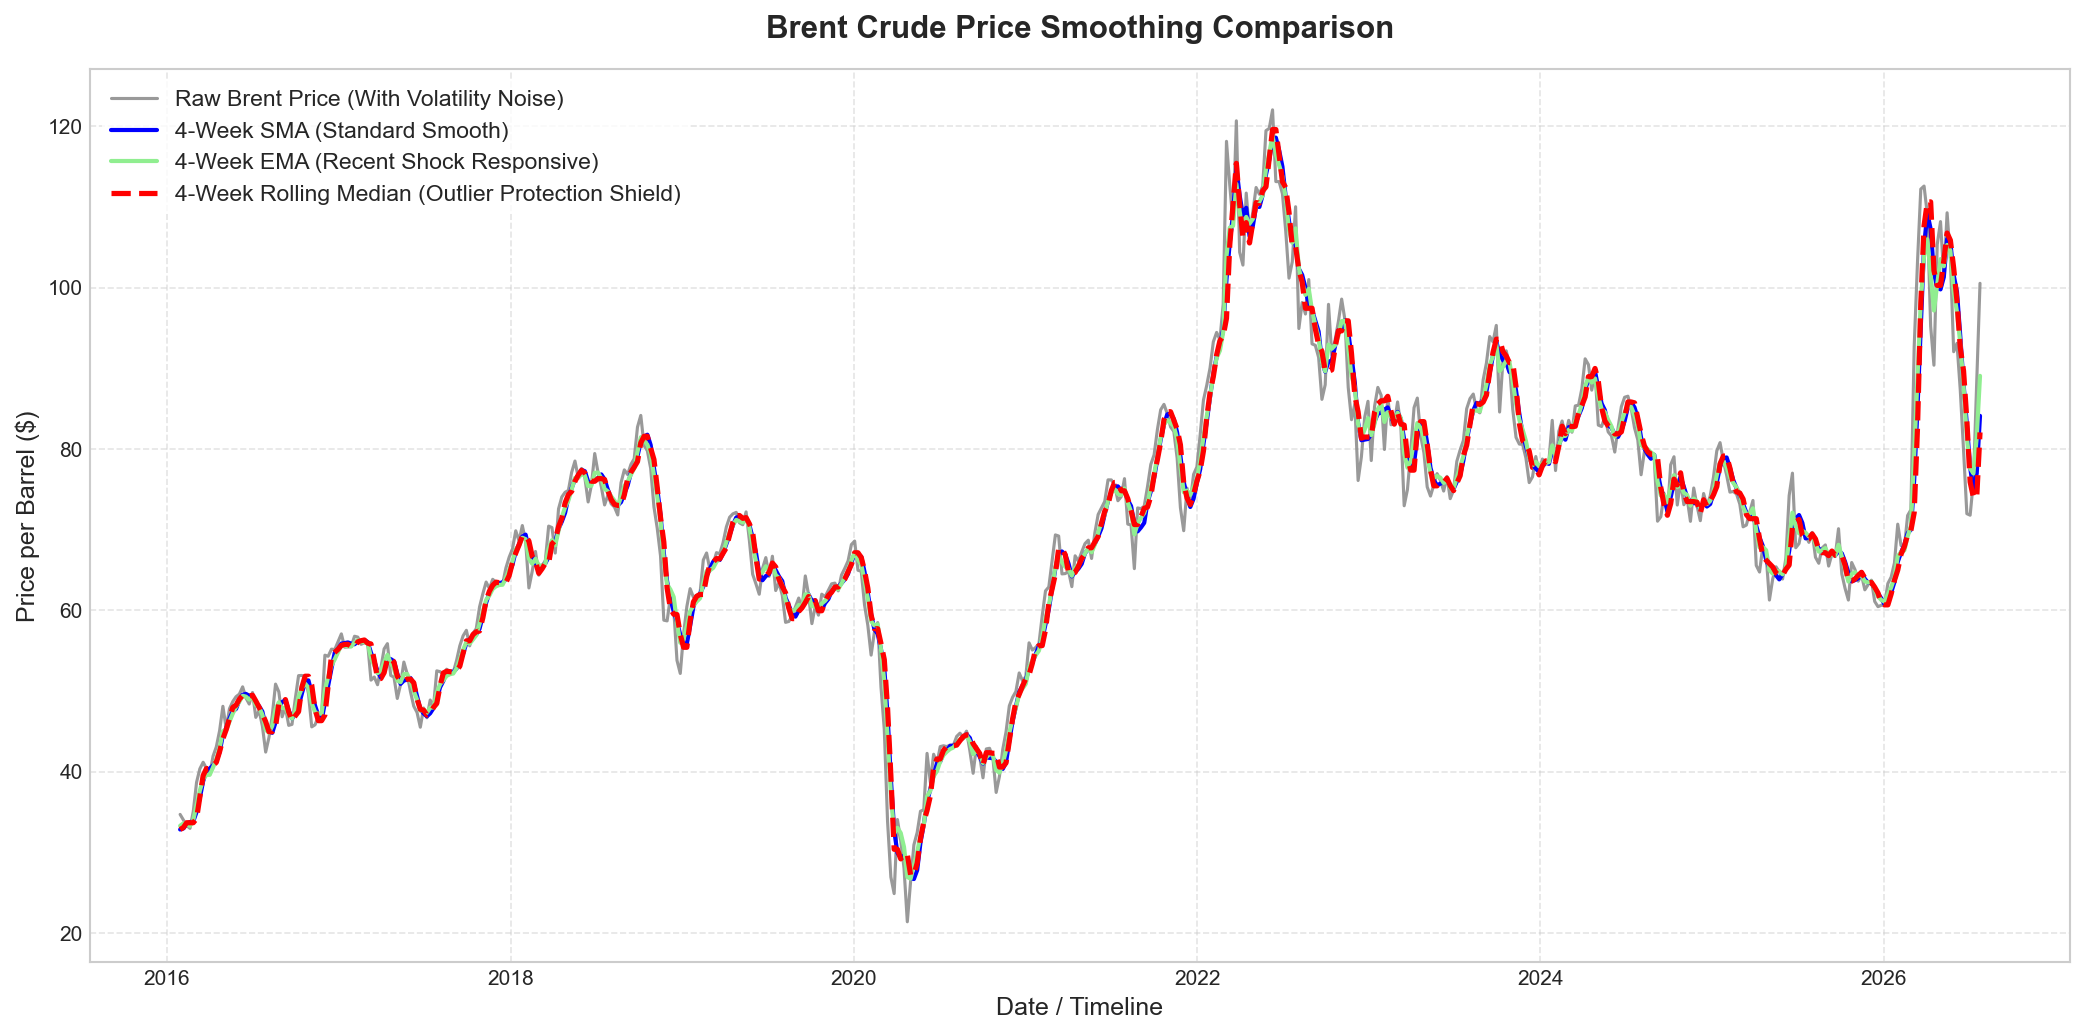

            Brent_Crude  WTI_Crude  US_Dollar_Index  VIX_Index  OPEC_Plus_Production
2026-06-26        71.99      69.23          101.360      18.41                26.937
2026-07-03        71.80      68.69          100.860      16.15                27.517
2026-07-10        76.01      71.41          100.970      15.03                27.517
2026-07-17        88.10      82.49          100.750      18.77                27.517
2026-07-24       100.52      92.19          101.437      18.70                27.517
Master Dataset Loaded from Notebook 01. Shape: (548, 13)


In [1]:
# Runs notebook 01 and imports all functions and variables created in it
%run data_collection_cleaning_EDA.ipynb

# Now master_dataset is automatically available!
print("Master Dataset Loaded from Notebook 01. Shape:", master_dataset.shape)

Starting the build of the model 

In [8]:
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np
import warnings
import itertools

In [9]:
# Suppress non-critical optimizer warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings("ignore")

# --- 1. ENSURE EXPLICIT FREQUENCY ---
master_dataset = master_dataset.asfreq('W-FRI')

In [4]:
# --- 2. TRAIN / TEST SPLIT (80% Train, 20% Test) ---
train_size = int(len(master_dataset) * 0.8)

train_data = master_dataset.iloc[:train_size].copy()
test_data = master_dataset.iloc[train_size:].copy()

# Enforce weekly frequency explicitly on train/test slices
train_data.index.freq = 'W-FRI'
test_data.index.freq = 'W-FRI'

# Target Variable (Y)
y_train = train_data['Brent_Crude']
y_test = test_data['Brent_Crude']

# Exogenous Variables (X) -> Exclude WTI_Crude to prevent severe multicollinearity
exog_cols = ['US_Dollar_Index', 'VIX_Index', 'OPEC_Plus_Production']
exog_train = train_data[exog_cols]
exog_test = test_data[exog_cols]

print(f"Data Split Complete: {len(y_train)} Training Weeks, {len(y_test)} Testing Weeks.")

Data Split Complete: 438 Training Weeks, 110 Testing Weeks.


In [5]:
# --- 3. FIT BASELINE SARIMAX MODEL ---
model = sm.tsa.statespace.SARIMAX(
    y_train,
    exog=exog_train,
    order=(1, 1, 1),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False,
    initialization='approximate_diffuse'
)

results = model.fit(method='lbfgs', disp=False)

print("\n--- BASELINE SARIMAX MODEL SUMMARY ---")
print(results.summary())


--- BASELINE SARIMAX MODEL SUMMARY ---
                               SARIMAX Results                                
Dep. Variable:            Brent_Crude   No. Observations:                  438
Model:               SARIMAX(1, 1, 1)   Log Likelihood               -1152.587
Date:                Fri, 24 Jul 2026   AIC                           2317.175
Time:                        00:21:10   BIC                           2341.668
Sample:                    01-29-2016   HQIC                          2326.839
                         - 06-14-2024                                         
Covariance Type:                  opg                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
US_Dollar_Index         -0.1808      0.164     -1.103      0.270      -0.502       0.141
VIX_Index               -0.2622      0.044     -5.981      0.

In [6]:
# --- 4. FORECAST & EVALUATION ---
predictions = results.predict(start=test_data.index[0], end=test_data.index[-1], exog=exog_test)

# Calculate Accuracy Metrics
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("\n--- BASELINE SARIMAX ACCURACY METRICS ---")
print(f"Mean Absolute Error (MAE):     ${mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print(f"R-Squared (R2 Score):          {r2:.4f}")


--- BASELINE SARIMAX ACCURACY METRICS ---
Mean Absolute Error (MAE):     $11.29
Root Mean Squared Error (RMSE): $13.03
R-Squared (R2 Score):          -0.0851


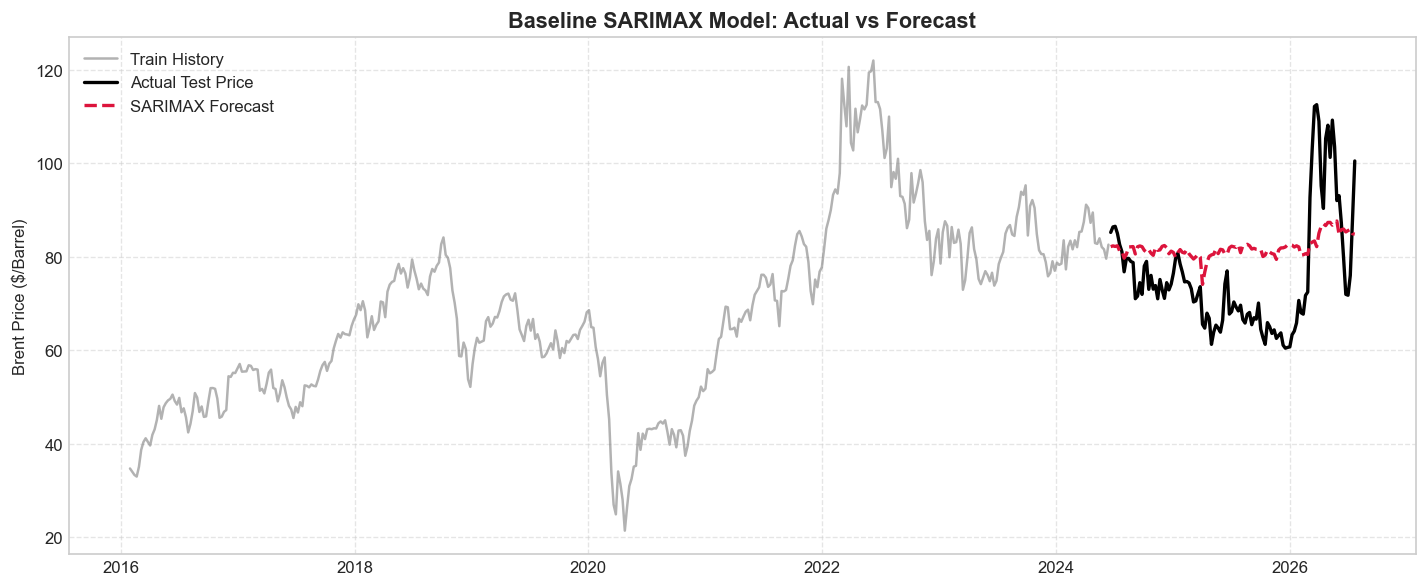

In [20]:
# --- 5. FORECAST PLOT ---
plt.figure(figsize=(12, 5), dpi=120)
plt.plot(train_data.index, y_train, label='Train History', color='grey', alpha=0.6)
plt.plot(test_data.index, y_test, label='Actual Test Price', color='black', linewidth=2)
plt.plot(test_data.index, predictions, label='SARIMAX Forecast', color='crimson', linestyle='--', linewidth=2)

plt.title('Baseline SARIMAX Model: Actual vs Forecast', fontsize=13, fontweight='bold')
plt.ylabel('Brent Price ($/Barrel)')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Parameter tweaking suggestion 

In [10]:
print("--- STARTING SARIMAX PARAMETER GRID SEARCH ---")

# Define the p, d, and q parameters to take any value between 0 and 2
p_values = range(0, 3)
d_values = [1] # We keep d=1 because your ADF test proved we need differencing
q_values = range(0, 3)

# Generate all different combinations of p, d and q triplets
pdq_combinations = list(itertools.product(p_values, d_values, q_values))

best_aic = float("inf")
best_params = None

# Loop through all combinations to find the best model
for param in pdq_combinations:
    try:
        temp_model = sm.tsa.statespace.SARIMAX(
            y_train,
            exog=exog_train,
            order=param,
            enforce_stationarity=False,
            enforce_invertibility=False,
            initialization='approximate_diffuse'
        )
        temp_results = temp_model.fit(method='lbfgs', disp=False)
        
        # Check if this model is the best one so far
        if temp_results.aic < best_aic:
            best_aic = temp_results.aic
            best_params = param
            
        print(f"Tested SARIMAX{param} - AIC: {temp_results.aic:.2f}")
    except:
        continue

print("\n--- GRID SEARCH COMPLETE ---")
print(f"The mathematically optimal parameters are SARIMAX{best_params} with an AIC of {best_aic:.2f}")

--- STARTING SARIMAX PARAMETER GRID SEARCH ---
Tested SARIMAX(0, 1, 0) - AIC: 2305.09
Tested SARIMAX(0, 1, 1) - AIC: 2315.38
Tested SARIMAX(0, 1, 2) - AIC: 2327.91
Tested SARIMAX(1, 1, 0) - AIC: 2307.06
Tested SARIMAX(1, 1, 1) - AIC: 2317.17
Tested SARIMAX(1, 1, 2) - AIC: 2328.69
Tested SARIMAX(2, 1, 0) - AIC: 2317.70
Tested SARIMAX(2, 1, 1) - AIC: 2321.62
Tested SARIMAX(2, 1, 2) - AIC: 2318.35

--- GRID SEARCH COMPLETE ---
The mathematically optimal parameters are SARIMAX(0, 1, 0) with an AIC of 2305.09


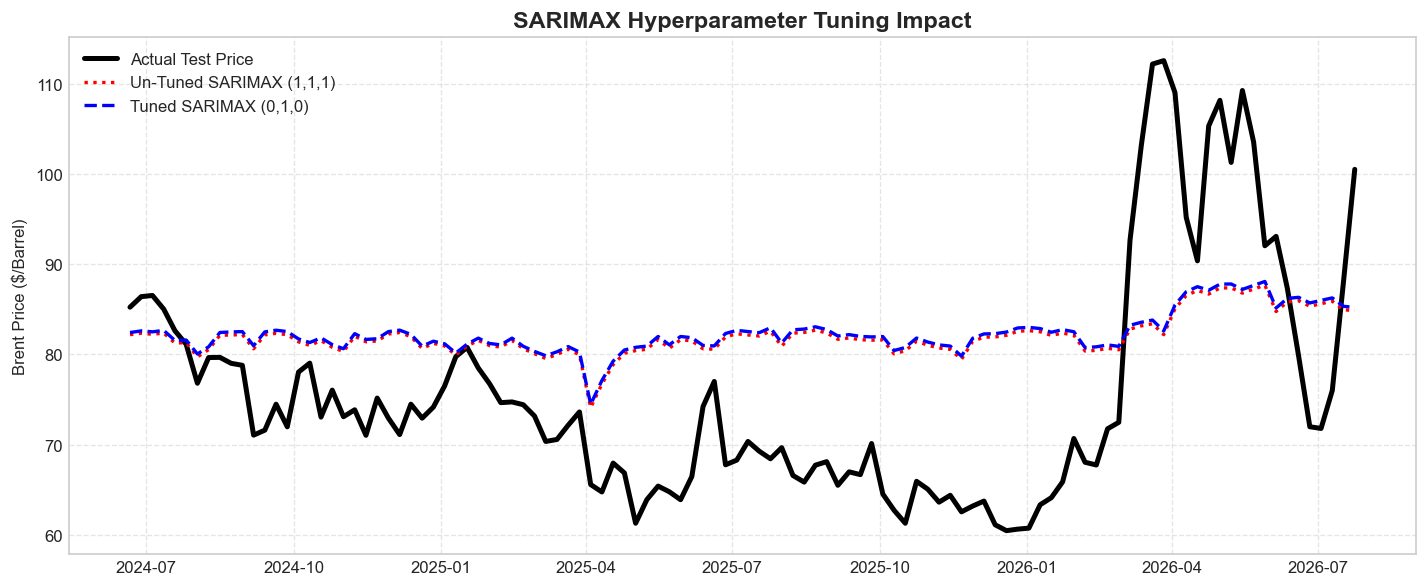

In [19]:
# Fit the Original Un-tuned Model (1, 1, 1)
model_untuned = sm.tsa.statespace.SARIMAX(y_train, exog=exog_train, order=(1, 1, 1), enforce_stationarity=False, enforce_invertibility=False, initialization='approximate_diffuse')
res_untuned = model_untuned.fit(method='lbfgs', disp=False)
pred_untuned = res_untuned.predict(start=test_data.index[0], end=test_data.index[-1], exog=exog_test)

# Fit the Optimal Grid-Searched Model (1, 1, 0)
model_tuned = sm.tsa.statespace.SARIMAX(y_train, exog=exog_train, order=(0, 1, 0), enforce_stationarity=False, enforce_invertibility=False, initialization='approximate_diffuse')
res_tuned = model_tuned.fit(method='lbfgs', disp=False)
pred_tuned = res_tuned.predict(start=test_data.index[0], end=test_data.index[-1], exog=exog_test)

# Plot the Before & After
plt.figure(figsize=(12, 5), dpi=120)
plt.plot(test_data.index, y_test, label='Actual Test Price', color='black', linewidth=3)
plt.plot(test_data.index, pred_untuned, label='Un-Tuned SARIMAX (1,1,1)', color='red', linestyle=':', linewidth=2)
plt.plot(test_data.index, pred_tuned, label='Tuned SARIMAX (0,1,0)', color='blue', linestyle='--', linewidth=2)

plt.title('SARIMAX Hyperparameter Tuning Impact', fontsize=14, fontweight='bold')
plt.ylabel('Brent Price ($/Barrel)')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

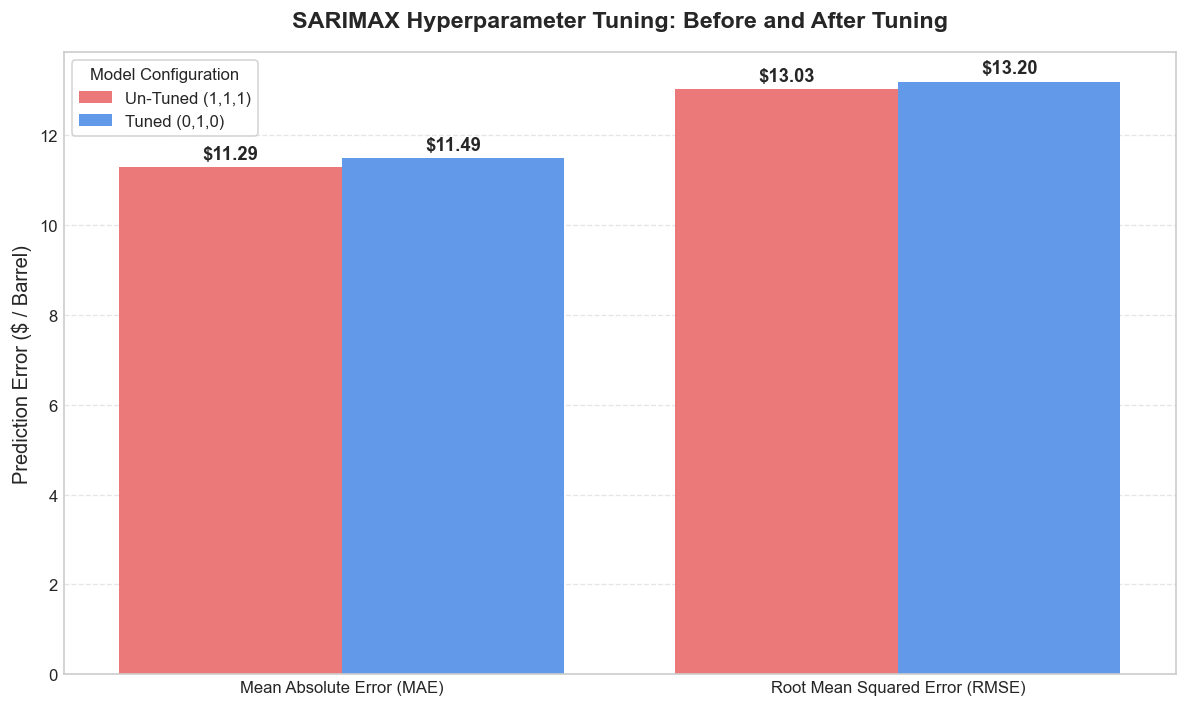

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Calculate exact errors from your existing prediction variables
mae_untuned = mean_absolute_error(y_test, pred_untuned)
mae_tuned = mean_absolute_error(y_test, pred_tuned)

rmse_untuned = np.sqrt(mean_squared_error(y_test, pred_untuned))
rmse_tuned = np.sqrt(mean_squared_error(y_test, pred_tuned))

# 2. Structure the data for Seaborn
tuning_df = pd.DataFrame({
    'Metric': ['Mean Absolute Error (MAE)', 'Mean Absolute Error (MAE)', 'Root Mean Squared Error (RMSE)', 'Root Mean Squared Error (RMSE)'],
    'Model State': ['Un-Tuned (1,1,1)', 'Tuned (0,1,0)', 'Un-Tuned (1,1,1)', 'Tuned (0,1,0)'],
    'Error Value ($)': [mae_untuned, mae_tuned, rmse_untuned, rmse_tuned]
})

# 3. Create the Grouped Bar Chart
plt.figure(figsize=(10, 6), dpi=120)
ax = sns.barplot(
    data=tuning_df, 
    x='Metric', 
    y='Error Value ($)', 
    hue='Model State', 
    palette=['#ff6666', '#4d94ff'] # Red for un-tuned, Blue for tuned
)

# 4. Clean up aesthetics for the presentation
plt.title('SARIMAX Hyperparameter Tuning: Before and After Tuning', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Prediction Error ($ / Barrel)', fontsize=12)
plt.xlabel('')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 5. Automatically attach the exact dollar amounts to the top of the bars
for p in ax.patches:
    if p.get_height() > 0: # Prevents labeling empty bars if they exist
        ax.annotate(f"${p.get_height():.2f}", 
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 8), 
                    textcoords='offset points', fontweight='bold', fontsize=11)

plt.legend(title='Model Configuration', loc='upper left', frameon=True)
plt.tight_layout()
plt.show()